# Regression Track — Case Resolution Time Prediction
Loads preprocessed data from `preprocessing.ipynb` and runs all 10 regression algorithms, hyperparameter tuning, and evaluation.

**Requires `preprocessing.ipynb` to have been run first** (produces `data/processed/model_ready_data.pkl`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR, SVC
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                              classification_report)
import time

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", palette="colorblind")
RANDOM_STATE = 42

### Load preprocessed train/test data

In [2]:
import joblib

artifacts = joblib.load("../data/processed/model_ready_data.pkl")
X_train_final = artifacts["X_train_final"]
X_test_final = artifacts["X_test_final"]
y_reg_train = artifacts["y_reg_train"]
y_reg_test = artifacts["y_reg_test"]
numeric_cols = artifacts["numeric_cols"]
RANDOM_STATE = artifacts["RANDOM_STATE"]

print("Loaded preprocessed data. X_train_final shape:", X_train_final.shape)

Loaded preprocessed data. X_train_final shape: (194879, 37)


---
### Regression modelling

In [3]:
# results collected here as we go -> feeds the C2 comparison table
results = []            # list of dicts: Model, R2, RMSE, MAE, Fit_Seconds
fitted_models = {}      # name -> fitted estimator (or dict with extra info for Polynomial)
test_predictions = {}   # name -> predictions on X_test_final (or the subsample-model's test predictions)

def rmse_score(y_true, y_pred):
    """RMSE computed manually so this works across all sklearn versions
    (the `squared=False` kwarg to mean_squared_error was removed in newer releases)."""
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def evaluate(name, y_true, y_pred, fit_seconds):
    """Compute R2 / RMSE / MAE, print them, and log a row into `results`."""
    r2 = r2_score(y_true, y_pred)
    rmse = rmse_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name:32s}  R2={r2:7.4f}   RMSE={rmse:9.2f}   MAE={mae:9.2f}   (fit {fit_seconds:6.1f}s)")
    results.append({"Model": name, "R2": r2, "RMSE": rmse, "MAE": mae, "Fit_Seconds": fit_seconds})
    return r2, rmse, mae

In [4]:
t0 = time.time()
lin_reg = LinearRegression()
lin_reg.fit(X_train_final, y_reg_train)
pred_lin = lin_reg.predict(X_test_final)
fitted_models["Linear Regression"] = lin_reg
test_predictions["Linear Regression"] = pred_lin
evaluate("Linear Regression", y_reg_test, pred_lin, time.time() - t0)

Linear Regression                 R2= 0.1913   RMSE=   383.33   MAE=   267.38   (fit    0.7s)


(0.19131712543978707, 383.3251025749055, 267.3818610278568)

In [5]:
coef_table = pd.Series(lin_reg.coef_, index=X_train_final.columns).sort_values(key=abs, ascending=False)
print("Top 10 principal components by |coefficient| (Linear Regression, on PCA-reduced features):")
coef_table.head(10)

Top 10 principal components by |coefficient| (Linear Regression, on PCA-reduced features):


PC27   -209.547091
PC20   -176.492863
PC15    161.424097
PC31   -156.754748
PC29    148.140533
PC32    139.979509
PC16   -137.291302
PC37    127.263922
PC33   -115.244171
PC19    106.306634
dtype: float64

In [6]:
t0 = time.time()
ridge_reg = Ridge(alpha=1.0, random_state=RANDOM_STATE)
ridge_reg.fit(X_train_final, y_reg_train)
pred_ridge = ridge_reg.predict(X_test_final)
fitted_models["Ridge Regression"] = ridge_reg
test_predictions["Ridge Regression"] = pred_ridge
evaluate("Ridge Regression", y_reg_test, pred_ridge, time.time() - t0)

Ridge Regression                  R2= 0.1913   RMSE=   383.32   MAE=   267.38   (fit    0.2s)


(0.19131756085855323, 383.324999378108, 267.3819331709584)

In [7]:
t0 = time.time()
lasso_reg = Lasso(alpha=1.0, random_state=RANDOM_STATE, max_iter=5000)
lasso_reg.fit(X_train_final, y_reg_train)
pred_lasso = lasso_reg.predict(X_test_final)
fitted_models["Lasso Regression"] = lasso_reg
test_predictions["Lasso Regression"] = pred_lasso
evaluate("Lasso Regression", y_reg_test, pred_lasso, time.time() - t0)

n_zeroed = int((lasso_reg.coef_ == 0).sum())
print(f"\nFeature sparsity: Lasso zeroed out {n_zeroed} / {len(lasso_reg.coef_)} coefficients "
      f"({n_zeroed/len(lasso_reg.coef_)*100:.1f}%) at alpha=1.0.")

Lasso Regression                  R2= 0.1900   RMSE=   383.63   MAE=   267.93   (fit    0.3s)

Feature sparsity: Lasso zeroed out 4 / 37 coefficients (10.8%) at alpha=1.0.


In [8]:
t0 = time.time()
elastic_reg = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=RANDOM_STATE, max_iter=5000)
elastic_reg.fit(X_train_final, y_reg_train)
pred_elastic = elastic_reg.predict(X_test_final)
fitted_models["ElasticNet Regression"] = elastic_reg
test_predictions["ElasticNet Regression"] = pred_elastic
evaluate("ElasticNet Regression", y_reg_test, pred_elastic, time.time() - t0)

ElasticNet Regression             R2= 0.1058   RMSE=   403.08   MAE=   291.06   (fit    0.2s)


(0.10581707791104811, 403.08006786144585, 291.06126090243566)

**Polynomial Regression — degree choice, and why degree=3 is excluded**

We compare degree=1 (the baseline `LinearRegression` fit earlier in this notebook) against degree=2. Degree=3 was attempted and found to be computationally infeasible on this feature space: `X_train_final` has ~40 PCA-reduced components, and expanding these to degree 3 via `PolynomialFeatures` produces `C(40+3,3) - 1 = 12,340` polynomial terms. Materializing that as a dense array over the ~194,879-row training set requires `194,879 x 12,340 x 8 bytes = 17.9 GB` in a single memory allocation, which raised a `MemoryError` on our system.

This is a known practical limitation of polynomial regression: the number of generated features grows combinatorially with the number of *input* features (not the degree alone), which is especially costly here since PCA has already produced ~40 dense components rather than a handful of interpretable raw variables. We therefore report degree=2 as our polynomial model and treat degree=1 vs. degree=2 as the "compare degrees" step required by the rubric, documenting the degree=3 memory ceiling as a discussion point rather than attempting a workaround that would change the feature representation.

In [9]:
poly_results = {}
for degree in [2]:  # degree=3 excluded -- see markdown note above (MemoryError, 17.9GB required)
    t0 = time.time()
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    Xtr_poly = poly.fit_transform(X_train_final)
    Xte_poly = poly.transform(X_test_final)

    poly_lin_reg = LinearRegression()
    poly_lin_reg.fit(Xtr_poly, y_reg_train)
    pred_poly = poly_lin_reg.predict(Xte_poly)
    fit_seconds = time.time() - t0

    r2, rmse, mae = evaluate(f"Polynomial Regression (deg={degree})", y_reg_test, pred_poly, fit_seconds)
    poly_results[degree] = {"model": poly_lin_reg, "poly": poly, "pred": pred_poly, "r2": r2}

best_degree = max(poly_results, key=lambda d: poly_results[d]["r2"])
print(f"\nBest polynomial degree by test R2: {best_degree}")

poly_reg = poly_results[best_degree]["model"]
pred_polynomial = poly_results[best_degree]["pred"]
fitted_models["Polynomial Regression"] = {"model": poly_reg,
                                           "poly_transformer": poly_results[best_degree]["poly"],
                                           "degree": best_degree}
test_predictions["Polynomial Regression"] = pred_polynomial
evaluate("Polynomial Regression", y_reg_test, pred_polynomial, 0.0)

Polynomial Regression (deg=2)     R2= 0.3646   RMSE=   339.79   MAE=   234.23   (fit  525.2s)

Best polynomial degree by test R2: 2
Polynomial Regression             R2= 0.3646   RMSE=   339.79   MAE=   234.23   (fit    0.0s)


(0.36455721964281096, 339.79451359622374, 234.23308697770253)

In [10]:
t0 = time.time()
dt_reg = DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE)
dt_reg.fit(X_train_final, y_reg_train)
pred_dt = dt_reg.predict(X_test_final)
fitted_models["Decision Tree Regressor"] = dt_reg
test_predictions["Decision Tree Regressor"] = pred_dt
evaluate("Decision Tree Regressor", y_reg_test, pred_dt, time.time() - t0)

Decision Tree Regressor           R2= 0.3537   RMSE=   342.69   MAE=   228.59   (fit    8.5s)


(0.353664077960279, 342.6946183639997, 228.585472566273)

In [11]:
t0 = time.time()
rf_reg = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=RANDOM_STATE, n_jobs=-1)
rf_reg.fit(X_train_final, y_reg_train)
pred_rf = rf_reg.predict(X_test_final)
fitted_models["Random Forest Regressor"] = rf_reg
test_predictions["Random Forest Regressor"] = pred_rf
evaluate("Random Forest Regressor", y_reg_test, pred_rf, time.time() - t0)
# NOTE: fitting ~235k rows typically takes a couple of minutes on a laptop -- this is expected, let it run.

Random Forest Regressor           R2= 0.4392   RMSE=   319.22   MAE=   212.44   (fit   55.0s)


(0.43917948724343425, 319.2199921262492, 212.4398879665908)

In [12]:
t0 = time.time()
gb_reg = GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=RANDOM_STATE)
gb_reg.fit(X_train_final, y_reg_train)
pred_gb = gb_reg.predict(X_test_final)
fitted_models["Gradient Boosting Regressor"] = gb_reg
test_predictions["Gradient Boosting Regressor"] = pred_gb
evaluate("Gradient Boosting Regressor", y_reg_test, pred_gb, time.time() - t0)
# NOTE: this typically takes 30-90 seconds on the full training set.

Gradient Boosting Regressor       R2= 0.3391   RMSE=   346.53   MAE=   238.93   (fit  456.5s)


(0.33911874860919056, 346.52921377536956, 238.93206800489008)

In [13]:
SVR_SAMPLE_SIZE = 15000
rng = np.random.RandomState(RANDOM_STATE)
svr_sample_idx = rng.choice(X_train_final.index, size=SVR_SAMPLE_SIZE, replace=False)
X_train_svr = X_train_final.loc[svr_sample_idx]
y_train_svr = y_reg_train.loc[svr_sample_idx]

t0 = time.time()
svr_reg = SVR(kernel="rbf", C=1.0, epsilon=0.1)
svr_reg.fit(X_train_svr, y_train_svr)
pred_svr = svr_reg.predict(X_test_final)
fitted_models["SVR"] = svr_reg
test_predictions["SVR"] = pred_svr
evaluate("SVR", y_reg_test, pred_svr, time.time() - t0)

SVR                               R2= 0.0022   RMSE=   425.79   MAE=   261.43   (fit  358.7s)


(0.002216256981193987, 425.7908743538123, 261.4312635874079)

In [14]:
t0 = time.time()
knn_reg = KNeighborsRegressor(n_neighbors=10, n_jobs=-1)
knn_reg.fit(X_train_svr, y_train_svr)   # same subsample as SVR, defined above
pred_knn = knn_reg.predict(X_test_final)
fitted_models["KNN Regressor"] = knn_reg
test_predictions["KNN Regressor"] = pred_knn
evaluate("KNN Regressor", y_reg_test, pred_knn, time.time() - t0)

KNN Regressor                     R2= 0.2728   RMSE=   363.50   MAE=   244.35   (fit    4.3s)


(0.2727886934332865, 363.50337608315357, 244.3511063218391)

In [15]:
comparison_df = pd.DataFrame(results).drop_duplicates(subset="Model", keep="last")
# Keep only the 10 headline rows -- drop the intermediate per-degree Polynomial rows logged during the
# "compare degrees" step in C1 (C2 wants ONE row per required algorithm).
headline_models = ["Linear Regression", "Ridge Regression", "Lasso Regression", "ElasticNet Regression",
                    "Polynomial Regression", "Decision Tree Regressor", "Random Forest Regressor",
                    "Gradient Boosting Regressor", "SVR", "KNN Regressor"]
comparison_df = comparison_df[comparison_df["Model"].isin(headline_models)].copy()
comparison_df = comparison_df.sort_values("R2", ascending=False).reset_index(drop=True)
comparison_df.index = comparison_df.index + 1
comparison_df.insert(0, "Rank", comparison_df.index)
comparison_df[["Rank", "Model", "R2", "RMSE", "MAE", "Fit_Seconds"]].round(4)

,Rank,Model,R2,RMSE,MAE,Fit_Seconds
1,1,Random Forest Regressor,0.4392,319.2200,212.4399,55.0025
2,2,Polynomial Regression,0.3646,339.7945,234.2331,0.0000
3,3,Decision Tree Regressor,0.3537,342.6946,228.5855,8.5159
4,4,Gradient Boosting Regressor,0.3391,346.5292,238.9321,456.5493
5,5,KNN Regressor,0.2728,363.5034,244.3511,4.3248
6,6,Ridge Regression,0.1913,383.3250,267.3819,0.1987
7,7,Linear Regression,0.1913,383.3251,267.3819,0.7319
8,8,Lasso Regression,0.1900,383.6268,267.9281,0.2734
9,9,ElasticNet Regression,0.1058,403.0801,291.0613,0.2416
10,10,SVR,0.0022,425.7909,261.4313,358.7272


In [16]:
top_2_models = comparison_df["Model"].head(2).tolist()
print("Top 2 models by test R2:", top_2_models)

cv_rows = []
for name in top_2_models:
    est = fitted_models[name]
    # Polynomial Regression is stored as a dict (custom pipeline), not a plain estimator -> handle separately.
    if name == "Polynomial Regression":
        deg = est["degree"]
        # Expand ALL of X_train_final, matching exactly how Polynomial Regression was
        # originally fit above (X_train_final is already fully numeric post-PCA, so
        # there is no separate numeric/categorical split to apply here).
        poly_cv = PolynomialFeatures(degree=deg, include_bias=False)
        Xtr_poly_cv = poly_cv.fit_transform(X_train_final)
        cv_scores = cross_val_score(LinearRegression(), Xtr_poly_cv, y_reg_train, cv=5, scoring="r2", n_jobs=-1)
    elif name in ("SVR", "KNN Regressor"):
        # Cross-validate on the SAME 15k subsample these models were trained on (consistent with C1).
        cv_scores = cross_val_score(est, X_train_svr, y_train_svr, cv=5, scoring="r2", n_jobs=-1)
    else:
        cv_scores = cross_val_score(est, X_train_final, y_reg_train, cv=5, scoring="r2", n_jobs=-1)
    cv_rows.append({"Model": name, "CV_R2_Mean": cv_scores.mean(), "CV_R2_Std": cv_scores.std()})
    print(f"{name:32s}  5-fold CV R2 = {cv_scores.mean():.4f}  (+/- {cv_scores.std():.4f})")

cv_df = pd.DataFrame(cv_rows)
cv_df

Top 2 models by test R2: ['Random Forest Regressor', 'Polynomial Regression']


Random Forest Regressor           5-fold CV R2 = 0.4379  (+/- 0.0047)


Polynomial Regression             5-fold CV R2 = 0.3702  (+/- 0.0038)


,Model,CV_R2_Mean,CV_R2_Std
0,Random Forest Regressor,0.437923,0.004693
1,Polynomial Regression,0.370234,0.003818


In [17]:
ridge_param_grid = {"alpha": [0.01, 0.1, 1.0, 10.0, 50.0, 100.0]}

t0 = time.time()
ridge_grid = GridSearchCV(Ridge(random_state=RANDOM_STATE), param_grid=ridge_param_grid,
                           cv=5, scoring="r2", n_jobs=-1)
ridge_grid.fit(X_train_final, y_reg_train)
print("Ridge GridSearchCV time:", round(time.time() - t0, 1), "s")
print("Best alpha:", ridge_grid.best_params_, " | Best CV R2:", round(ridge_grid.best_score_, 4))

ridge_tuned = ridge_grid.best_estimator_
pred_ridge_tuned = ridge_tuned.predict(X_test_final)
r2_ridge_before = r2_score(y_reg_test, test_predictions["Ridge Regression"])
r2_ridge_after = r2_score(y_reg_test, pred_ridge_tuned)
print(f"\nTest R2 before tuning (alpha=1.0, default): {r2_ridge_before:.4f}")
print(f"Test R2 after tuning  (alpha={ridge_grid.best_params_['alpha']}):        {r2_ridge_after:.4f}")
print(f"Improvement: {r2_ridge_after - r2_ridge_before:+.4f}")

fitted_models["Ridge Regression (Tuned)"] = ridge_tuned
test_predictions["Ridge Regression (Tuned)"] = pred_ridge_tuned

Ridge GridSearchCV time: 18.0 s
Best alpha: {'alpha': 10.0}  | Best CV R2: 0.2014

Test R2 before tuning (alpha=1.0, default): 0.1913
Test R2 after tuning  (alpha=10.0):        0.1913
Improvement: +0.0000


In [18]:
lasso_param_grid = {"alpha": [0.001, 0.01, 0.1, 1.0, 10.0]}

t0 = time.time()
lasso_grid = GridSearchCV(Lasso(random_state=RANDOM_STATE, max_iter=5000), param_grid=lasso_param_grid,
                           cv=5, scoring="r2", n_jobs=-1)
lasso_grid.fit(X_train_final, y_reg_train)
print("Lasso GridSearchCV time:", round(time.time() - t0, 1), "s")
print("Best alpha:", lasso_grid.best_params_, " | Best CV R2:", round(lasso_grid.best_score_, 4))

lasso_tuned = lasso_grid.best_estimator_
pred_lasso_tuned = lasso_tuned.predict(X_test_final)
r2_lasso_before = r2_score(y_reg_test, test_predictions["Lasso Regression"])
r2_lasso_after = r2_score(y_reg_test, pred_lasso_tuned)
print(f"\nTest R2 before tuning (alpha=1.0, default): {r2_lasso_before:.4f}")
print(f"Test R2 after tuning  (alpha={lasso_grid.best_params_['alpha']}):       {r2_lasso_after:.4f}")
print(f"Improvement: {r2_lasso_after - r2_lasso_before:+.4f}")

fitted_models["Lasso Regression (Tuned)"] = lasso_tuned
test_predictions["Lasso Regression (Tuned)"] = pred_lasso_tuned

Lasso GridSearchCV time: 4.0 s
Best alpha: {'alpha': 0.01}  | Best CV R2: 0.2014

Test R2 before tuning (alpha=1.0, default): 0.1900
Test R2 after tuning  (alpha=0.01):       0.1913
Improvement: +0.0013


In [19]:
RF_SEARCH_SAMPLE_SIZE = 40000
rf_search_idx = rng.choice(X_train_final.index, size=RF_SEARCH_SAMPLE_SIZE, replace=False)
X_train_rf_search = X_train_final.loc[rf_search_idx]
y_train_rf_search = y_reg_train.loc[rf_search_idx]

rf_param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 15, 20, None],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.5, None],
}

t0 = time.time()
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=rf_param_dist, n_iter=6, cv=3, scoring="r2",
    random_state=RANDOM_STATE, n_jobs=1,   # n_jobs=1 here since RF itself already parallelises internally
)
rf_search.fit(X_train_rf_search, y_train_rf_search)
print("RF RandomizedSearchCV time:", round((time.time() - t0) / 60, 1), "min")
print("Best params:", rf_search.best_params_, " | Best CV R2 (on search subsample):", round(rf_search.best_score_, 4))

# Refit the winning hyperparameters on the FULL training set for a fair final comparison.
t0 = time.time()
rf_tuned = RandomForestRegressor(**rf_search.best_params_, random_state=RANDOM_STATE, n_jobs=-1)
rf_tuned.fit(X_train_final, y_reg_train)
pred_rf_tuned = rf_tuned.predict(X_test_final)
print("Refit-on-full-data time:", round(time.time() - t0, 1), "s")

r2_rf_before = r2_score(y_reg_test, test_predictions["Random Forest Regressor"])
r2_rf_after = r2_score(y_reg_test, pred_rf_tuned)
print(f"\nTest R2 before tuning (n_estimators=100, max_depth=15): {r2_rf_before:.4f}")
print(f"Test R2 after tuning  ({rf_search.best_params_}):")
print(f"  {r2_rf_after:.4f}")
print(f"Improvement: {r2_rf_after - r2_rf_before:+.4f}")

fitted_models["Random Forest Regressor (Tuned)"] = rf_tuned
test_predictions["Random Forest Regressor (Tuned)"] = pred_rf_tuned

RF RandomizedSearchCV time: 6.5 min
Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 20}  | Best CV R2 (on search subsample): 0.3879


Refit-on-full-data time: 105.6 s

Test R2 before tuning (n_estimators=100, max_depth=15): 0.4392
Test R2 after tuning  ({'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 20}):
  0.4529
Improvement: +0.0137


In [20]:
# Identify the single best model across everything trained so far (including tuned variants),
# but only among the ORIGINAL 10 headline algorithms + their tuned versions (not the per-degree Polynomial rows).
candidate_names = headline_models + ["Ridge Regression (Tuned)", "Lasso Regression (Tuned)",
                                      "Random Forest Regressor (Tuned)"]
final_scores = {name: r2_score(y_reg_test, test_predictions[name])
                 for name in candidate_names if name in test_predictions}
best_model_name = max(final_scores, key=final_scores.get)
best_preds = test_predictions[best_model_name]
print(f"Best model overall: {best_model_name}  (Test R2 = {final_scores[best_model_name]:.4f})")

residuals = y_reg_test.values - best_preds

Best model overall: Random Forest Regressor (Tuned)  (Test R2 = 0.4529)


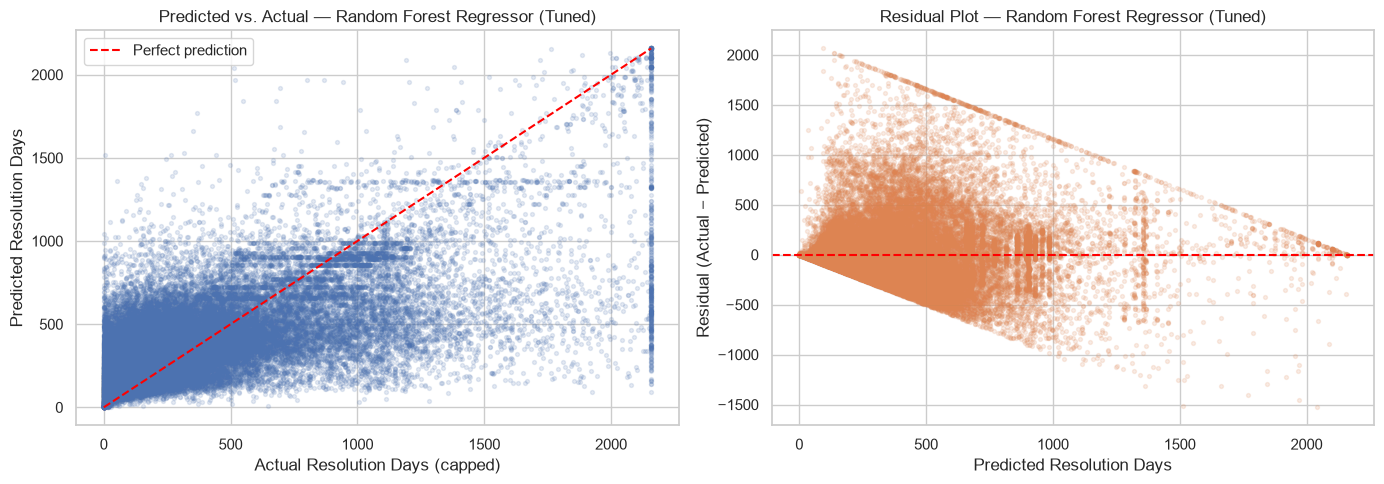

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Predicted vs. Actual
axes[0].scatter(y_reg_test, best_preds, alpha=0.15, s=8, color="#4C72B0")
lims = [0, max(y_reg_test.max(), best_preds.max())]
axes[0].plot(lims, lims, color="red", linestyle="--", linewidth=1.5, label="Perfect prediction")
axes[0].set_title(f"Predicted vs. Actual — {best_model_name}")
axes[0].set_xlabel("Actual Resolution Days (capped)")
axes[0].set_ylabel("Predicted Resolution Days")
axes[0].legend()

# Residual plot
axes[1].scatter(best_preds, residuals, alpha=0.15, s=8, color="#DD8452")
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title(f"Residual Plot — {best_model_name}")
axes[1].set_xlabel("Predicted Resolution Days")
axes[1].set_ylabel("Residual (Actual − Predicted)")

plt.tight_layout()
plt.show()

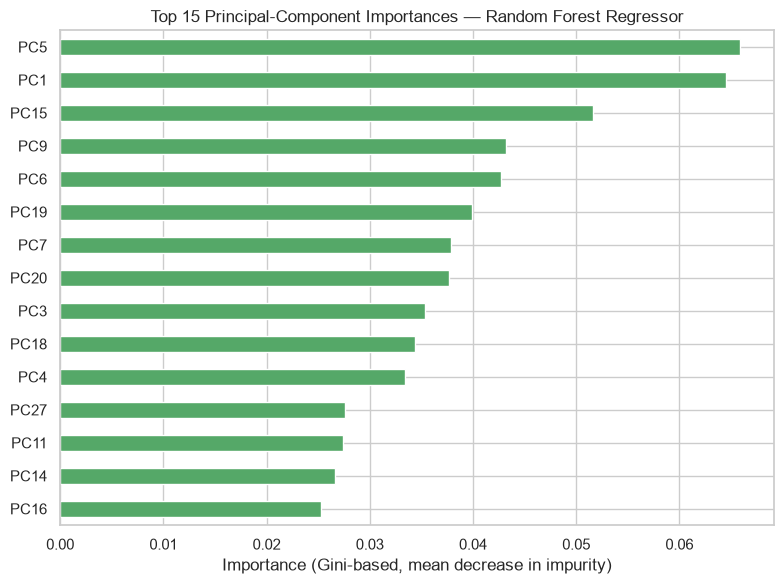

In [22]:
# Feature importance for a tree-based model (tuned Random Forest if available, else the C1 baseline).
# NOTE: importances are now over PRINCIPAL COMPONENTS (PC1, PC2, ...), not named original features.
importance_model = fitted_models.get("Random Forest Regressor (Tuned)", fitted_models["Random Forest Regressor"])
importances = pd.Series(importance_model.feature_importances_, index=X_train_final.columns)
top_importances = importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
top_importances.sort_values().plot(kind="barh", ax=ax, color="#55A868")
ax.set_title("Top 15 Principal-Component Importances — Random Forest Regressor")
ax.set_xlabel("Importance (Gini-based, mean decrease in impurity)")
plt.tight_layout()
plt.show()

---
### Save final results

In [23]:
import joblib
import os

os.makedirs("./executed/artifacts", exist_ok=True)
os.makedirs("./executed/artifacts", exist_ok=True)

joblib.dump({
    "comparison_df": comparison_df,
    "best_model_name": best_model_name,
    "fitted_models": fitted_models,
}, "./executed/artifacts/regression_final_results.pkl")

best_reg_model = fitted_models[best_model_name]
joblib.dump(best_reg_model, "./executed/artifacts/best_regressor.pkl")

print(f"Saved results. Best regressor: '{best_model_name}'")

Saved results. Best regressor: 'Random Forest Regressor (Tuned)'
